In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('data/WA_Fn-UseC_-HR-Employee-Attrition.csv')

In [4]:
df = df.drop(['EmployeeCount', 'StandardHours', 'Over18','EmployeeNumber'], axis=1)

In [7]:
len(df.columns)

31

In [9]:
X = df.drop(columns="Attrition")

In [12]:
len(X.columns)

30

In [15]:
y = df['Attrition'].map({"No":0,"Yes":1})

In [16]:
y

0       1
1       0
2       1
3       0
4       0
       ..
1465    0
1466    0
1467    0
1468    0
1469    0
Name: Attrition, Length: 1470, dtype: int64

In [17]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "No", 1: "Yes"}))

print("\nFeature columns:")
print(X.columns.tolist())

X shape: (1470, 30)
y shape: (1470,)

Target distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Feature columns:
['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


### Split the data into training and testing sets

In [23]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [24]:
print("X_train",X_train.shape)
print("X_test",X_test.shape)
print("y_train",y_train.shape)
print("y_test",y_test.shape)

X_train (1176, 30)
X_test (294, 30)
y_train (1176,)
y_test (294,)


In [25]:
print("\nAttrition proportion in training set:")
print(y_train.value_counts(normalize=True).round(3))

print("\nAttrition proportion in test set:")
print(y_test.value_counts(normalize=True).round(3))


Attrition proportion in training set:
Attrition
0    0.838
1    0.162
Name: proportion, dtype: float64

Attrition proportion in test set:
Attrition
0    0.84
1    0.16
Name: proportion, dtype: float64


### Identify numerical and categorical features

In [26]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

In [28]:
print("Numerical Columns: ",len(num_cols))
print(num_cols)
print("Categorical Features: ",len(cat_cols))
print(cat_cols)

Numerical Columns:  23
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical Features:  7
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


### Build the preprocessing pipeline

In [29]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

In [30]:
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown="ignore")

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ("Numerical_Feature",num_transformer,num_cols),
        ("Categorical",cat_transformer,cat_cols)
    ]
)

In [37]:
model_pipeline = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("Model",LogisticRegression(max_iter=2000,random_state=42))
    ]
)

In [38]:

print("\nPipeline steps:", model_pipeline.named_steps.keys())


Pipeline steps: dict_keys(['preprocessor', 'Model'])


### Train the Logistic Regression model and evaluate its performance.

###### 1. Train the Model

In [39]:
model_pipeline.fit(X_train,y_train)
print("Model Trained Successfully!")

Model Trained Successfully!


In [40]:
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Age','BusinessTravel','DailyRate',...,'YearsInCurrentRole', 'YearsSinceLastPromotion','YearsWithCurrManager']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical_Feature', ...), ('Categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default 

###### 2. Generate Predictions

In [47]:
y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:,-1]

print("Actual values: ",y_test.iloc[:30].tolist())
print("Predicted values: ",y_pred[:30].tolist())
print("Probabilities:    ", y_prob[:30].round(3).tolist())

Actual values:  [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1]
Predicted values:  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
Probabilities:     [0.077, 0.003, 0.165, 0.005, 0.316, 0.269, 0.008, 0.017, 0.004, 0.095, 0.055, 0.076, 0.372, 0.181, 0.281, 0.412, 0.016, 0.007, 0.275, 0.013, 0.442, 0.112, 0.106, 0.016, 0.005, 0.526, 0.09, 0.065, 0.008, 0.016]


###### 3.Calculate evaluation metrics

In [49]:
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix, classification_report, f1_score, recall_score,roc_auc_score

In [51]:
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:   ", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score: ", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob), 4))

Accuracy:  0.8605
Precision: 0.6154
Recall:    0.3404
F1-score:  0.4384
ROC-AUC:   0.8115


In [52]:
print("\nDetailed Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Stayed (No)", "Left (Yes)"],
        zero_division=0
    )
)


Detailed Classification Report:

              precision    recall  f1-score   support

 Stayed (No)       0.88      0.96      0.92       247
  Left (Yes)       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



Understand the confusion matrix

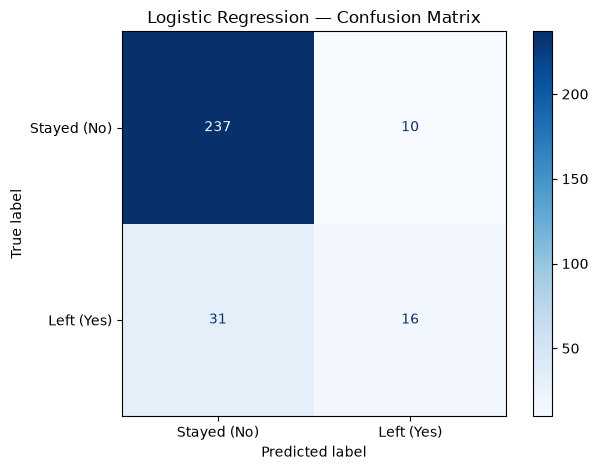

True Negatives  (TN): 237
False Positives (FP): 10
False Negatives (FN): 31
True Positives  (TP): 16


In [54]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (No)", "Left (Yes)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives  (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives  (TP):", tp)

Plot the ROC curve

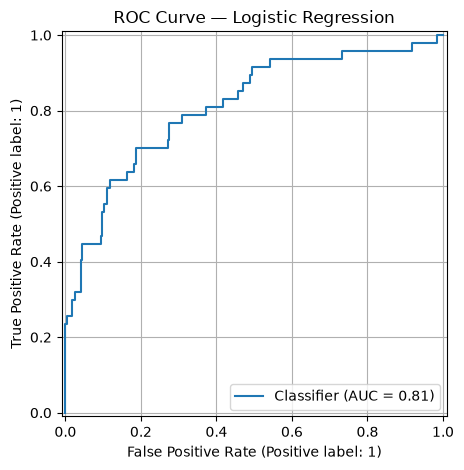

In [55]:

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve — Logistic Regression")
plt.grid(True)
plt.tight_layout()
plt.show()

## MARKDOWN

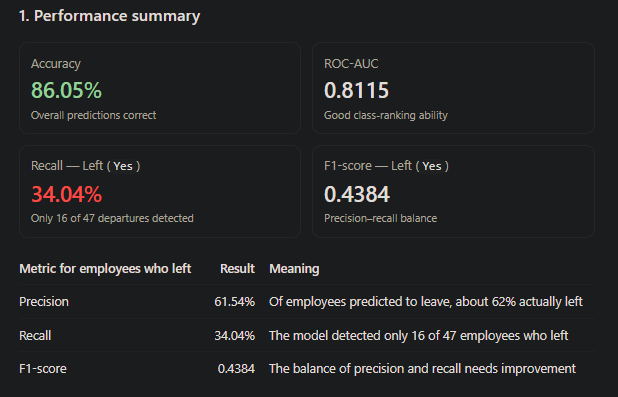

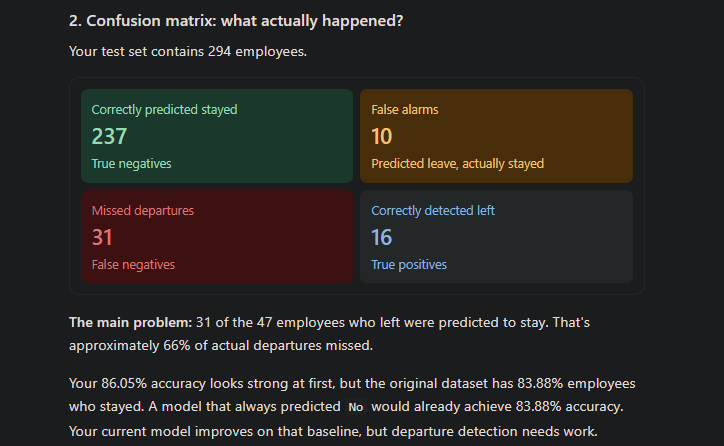